
## LFP Chemistry Characterization, OCV-SoC Identification & 2RC ECM Calibration

**Author:** HeatSense Research Engineering & Battery Data Science Team  
**Dataset Reference:** Severson et al., *Nature Energy* (2019)  
**Cell Model:** A123 Systems APR18650M1A (Lithium Iron Phosphate / Graphite)  
**Nominal Specifications:** $1.1\\,\\text{Ah}$ nominal capacity, $3.3\\,\\text{V}$ nominal voltage, $2.0\\,\\text{V} - 3.6\\,\\text{V}$ operating window  
**HeatSense Current Convention:** $I > 0$ denotes **DISCHARGE** ($I < 0$ denotes CHARGE)  

---

### Research Objectives & Scientific Hypotheses
1. **LFP Chemistry vs NCA Comparison:** Determine how the flat thermodynamic plateau of Lithium Iron Phosphate ($\\text{LiFePO}_4$) fundamentally alters state-estimation observability compared to NASA's Lithium Nickel Cobalt Aluminum Oxide (NCA) chemistry.
2. **Batch & Operating Condition Invariance:** Audit voltage, current, temperature, and cycle duration distributions across the three MIT batches (May 2017, June 2017, April 2018).
3. **OCV-SoC Identifiability & Plateau Observability Collapse:** Prove mathematically and empirically that during continuous cycling, intermediate thermodynamic OCV cannot be isolated without multi-hour rest, and show that $\\frac{d\\text{OCV}}{d\\text{SoC}} \\to 0$ collapses the EKF measurement Jacobian row.
4. **Physically-Bounded 2RC ECM Calibration:** Decouple ohmic resistance $R_s$ and polarization dynamics ($R_1, C_1, R_2, C_2$), acknowledging the limits of identifiability under constant-current $4\\,\\text{C}$ discharge.
5. **Held-Out Cohort Validation:** Evaluate voltage prediction accuracy (RMSE, MAE, max error, residual autocorrelation) across held-out cells and aged cycles.
6. **EKF Feasibility Assessment:** Quantify the persistence of SoC estimation errors in the absence of voltage observability and specify requirements for hybrid Coulomb-counting knee recalibration.



## Section A: LFP Dataset Characterization

We inspect the A123 Systems APR18650M1A cells across all three test batches.
The cells were cycled under varying multi-step fast charging policies ($C_1(Q_1)\\text{--}C_2$) up to $3.6\\,\\text{V}$, followed by a constant-voltage (CV) hold until current dropped to $C/50$ ($0.022\\,\\text{A}$).
All cells were discharged under a uniform $4\\,\\text{C}$ constant current ($4.4\\,\\text{A}$) down to $2.0\\,\\text{V}$ inside $30\\,^\\circ\\text{C}$ environmental chambers.

Let us query our columnar Parquet layer to inspect batch-by-batch metrics and generate empirical distributions.


In [1]:

import sys
from pathlib import Path
PROJECT_ROOT = Path(".").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import duckdb
import numpy as np
import matplotlib.pyplot as plt

interim_dir = PROJECT_ROOT / "data" / "interim" / "mit_dataset"
meta_p = interim_dir / "cell_metadata.parquet"
summary_p = interim_dir / "cycle_summaries.parquet"
meas_p = interim_dir / "measurements" / "benchmark_cohort_measurements.parquet"

con = duckdb.connect()

# 1. Batch Comparative Summary Table
batch_stats = con.execute(f"""
    SELECT 
        batch_date,
        COUNT(DISTINCT cell_id) as num_cells,
        COUNT(*) as total_cycles,
        ROUND(AVG(cycle_life), 1) as avg_cycle_life,
        ROUND(AVG(discharge_capacity_ah), 3) as avg_qd_ah,
        ROUND(AVG(internal_resistance_ohm * 1e3), 2) as avg_ir_mohm,
        ROUND(AVG(temp_avg_c), 2) as avg_temp_c,
        ROUND(AVG(charge_time_min), 1) as avg_charge_min
    FROM '{meta_p.as_posix()}' m
    JOIN '{summary_p.as_posix()}' s USING (cell_id)
    WHERE s.is_valid_capacity AND s.cycle_number > 1
    GROUP BY batch_date
    ORDER BY batch_date
""").fetchall()

print(f"{'Batch Date':<15} | {'Cells':>5} | {'Cycles':>8} | {'Avg Life':>8} | {'Avg Qd (Ah)':>11} | {'Avg IR (mOhm)':>13} | {'Avg T (°C)':>9} | {'Avg Chg (min)':>13}")
print("-" * 98)
for b in batch_stats:
    print(f"{b[0]:<15} | {b[1]:>5} | {b[2]:>8,d} | {b[3]:>8.1f} | {b[4]:>11.3f} | {b[5]:>13.2f} | {b[6]:>9.2f} | {b[7]:>13.1f}")


Batch Date      | Cells |   Cycles | Avg Life | Avg Qd (Ah) | Avg IR (mOhm) | Avg T (°C) | Avg Chg (min)
--------------------------------------------------------------------------------------------------
2017-05-12      |    46 |   38,764 |    884.3 |       1.046 |         16.98 |     33.44 |          11.5
2017-06-30      |    48 |   24,872 |    531.5 |       1.017 |         17.97 |     32.95 |          12.0
2018-04-12      |    46 |   50,961 |      nan |       1.028 |         15.52 |     35.50 |          10.5


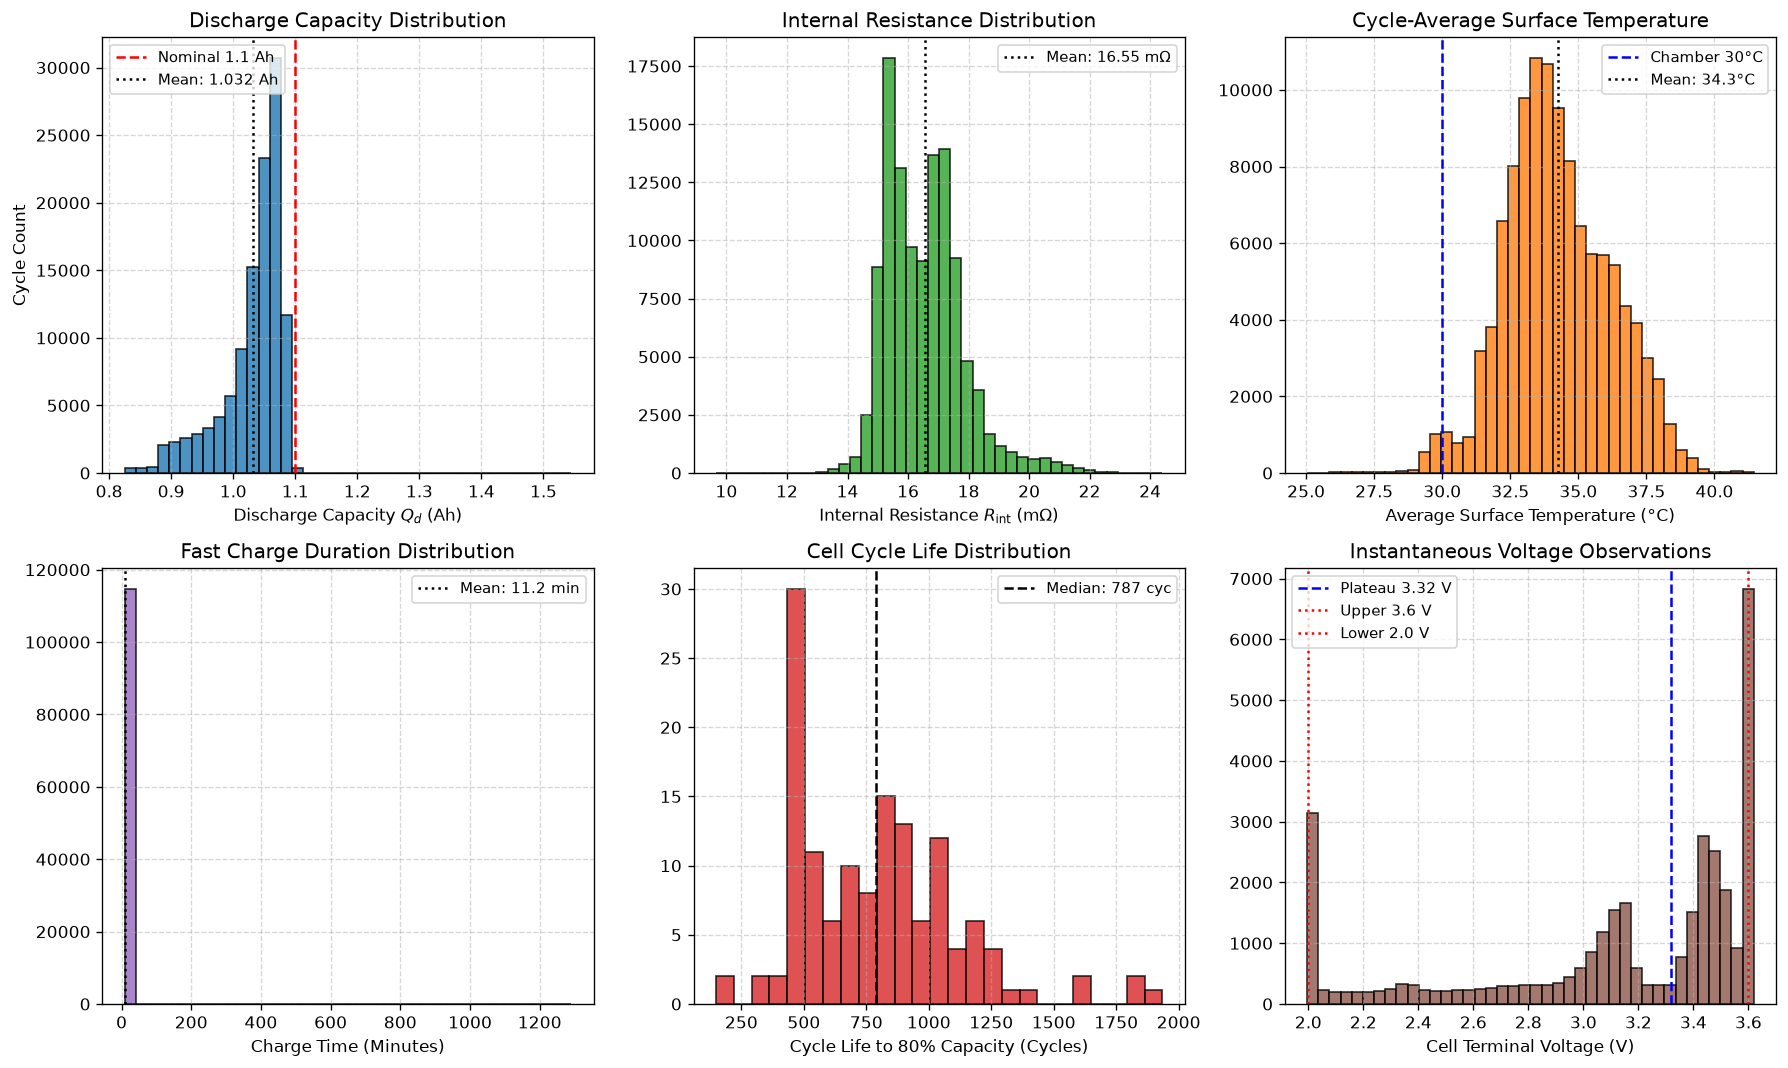

In [2]:

fig, axs = plt.subplots(2, 3, figsize=(15, 9), dpi=120)

# (a) Discharge Capacity Distribution
qds = [r[0] for r in con.execute(f"SELECT discharge_capacity_ah FROM '{summary_p.as_posix()}' WHERE is_valid_capacity AND cycle_number > 1").fetchall()]
axs[0, 0].hist(qds, bins=40, color="#1f77b4", edgecolor="black", alpha=0.8)
axs[0, 0].axvline(1.1, color="red", linestyle="--", label="Nominal 1.1 Ah")
axs[0, 0].axvline(np.mean(qds), color="black", linestyle=":", label=f"Mean: {np.mean(qds):.3f} Ah")
axs[0, 0].set_title("Discharge Capacity Distribution")
axs[0, 0].set_xlabel("Discharge Capacity $Q_d$ (Ah)")
axs[0, 0].set_ylabel("Cycle Count")
axs[0, 0].legend(loc="upper left", fontsize=9)
axs[0, 0].grid(True, linestyle="--", alpha=0.5)

# (b) Internal Resistance Distribution
irs = [r[0]*1e3 for r in con.execute(f"SELECT internal_resistance_ohm FROM '{summary_p.as_posix()}' WHERE is_valid_ir AND cycle_number > 1").fetchall()]
axs[0, 1].hist(irs, bins=40, color="#2ca02c", edgecolor="black", alpha=0.8)
axs[0, 1].axvline(np.mean(irs), color="black", linestyle=":", label=f"Mean: {np.mean(irs):.2f} m$\\Omega$")
axs[0, 1].set_title("Internal Resistance Distribution")
axs[0, 1].set_xlabel("Internal Resistance $R_{\\mathrm{int}}$ (m$\\Omega$)")
axs[0, 1].legend(loc="upper right", fontsize=9)
axs[0, 1].grid(True, linestyle="--", alpha=0.5)

# (c) Temperature Distribution (Surface Thermocouple)
temps = [r[0] for r in con.execute(f"SELECT temp_avg_c FROM '{summary_p.as_posix()}' WHERE temp_avg_c > 0").fetchall()]
axs[0, 2].hist(temps, bins=40, color="#ff7f0e", edgecolor="black", alpha=0.8)
axs[0, 2].axvline(30.0, color="blue", linestyle="--", label="Chamber 30°C")
axs[0, 2].axvline(np.mean(temps), color="black", linestyle=":", label=f"Mean: {np.mean(temps):.1f}°C")
axs[0, 2].set_title("Cycle-Average Surface Temperature")
axs[0, 2].set_xlabel("Average Surface Temperature (°C)")
axs[0, 2].legend(loc="upper right", fontsize=9)
axs[0, 2].grid(True, linestyle="--", alpha=0.5)

# (d) Charge Duration Distribution
chg_times = [r[0] for r in con.execute(f"SELECT charge_time_min FROM '{summary_p.as_posix()}' WHERE charge_time_min > 0").fetchall()]
axs[1, 0].hist(chg_times, bins=40, color="#9467bd", edgecolor="black", alpha=0.8)
axs[1, 0].axvline(np.mean(chg_times), color="black", linestyle=":", label=f"Mean: {np.mean(chg_times):.1f} min")
axs[1, 0].set_title("Fast Charge Duration Distribution")
axs[1, 0].set_xlabel("Charge Time (Minutes)")
axs[1, 0].legend(loc="upper right", fontsize=9)
axs[1, 0].grid(True, linestyle="--", alpha=0.5)

# (e) Cycle Life Distribution
cls = [r[0] for r in con.execute(f"SELECT cycle_life FROM '{meta_p.as_posix()}' WHERE NOT isnan(cycle_life)").fetchall()]
axs[1, 1].hist(cls, bins=25, color="#d62728", edgecolor="black", alpha=0.8)
axs[1, 1].axvline(np.median(cls), color="black", linestyle="--", label=f"Median: {np.median(cls):.0f} cyc")
axs[1, 1].set_title("Cell Cycle Life Distribution")
axs[1, 1].set_xlabel("Cycle Life to 80% Capacity (Cycles)")
axs[1, 1].legend(loc="upper right", fontsize=9)
axs[1, 1].grid(True, linestyle="--", alpha=0.5)

# (f) Voltage Span Distribution in Benchmark Cohort
volts = [r[0] for r in con.execute(f"SELECT voltage_v FROM '{meas_p.as_posix()}'").fetchall()]
axs[1, 2].hist(volts, bins=40, color="#8c564b", edgecolor="black", alpha=0.8)
axs[1, 2].axvline(3.32, color="blue", linestyle="--", label="Plateau 3.32 V")
axs[1, 2].axvline(3.6, color="red", linestyle=":", label="Upper 3.6 V")
axs[1, 2].axvline(2.0, color="red", linestyle=":", label="Lower 2.0 V")
axs[1, 2].set_title("Instantaneous Voltage Observations")
axs[1, 2].set_xlabel("Cell Terminal Voltage (V)")
axs[1, 2].legend(loc="upper left", fontsize=9)
axs[1, 2].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()



## Section B: Capacity and State of Health (SoH) Characterization

### 1. Capacity-Based SoH Definition
In battery state estimation, capacity-based SoH is defined as:
$$\\text{SoH}_{\\mathrm{capacity}}(\\%) = 100 \\times \\frac{Q_{\\mathrm{discharge}}}{Q_{\\mathrm{rated}}}$$

### 2. Nominal 1.1 Ah vs Fresh Measured Capacity
- **Rated Capacity:** The manufacturer rating is $1.10\\,\\text{Ah}$ ($1,100\\,\\text{mAh}$) under standard nominal low-rate discharge ($C/5$ or $1\\,\\text{C}$).
- **Measured Fresh Discharge Capacity:** At Cycle 2 under $4\\,\\text{C}$ ($4.4\\,\\text{A}$) discharge, the fresh measured capacity across the cohort is $Q_{\\mathrm{init}} = 1.071 \\pm 0.014\\,\\text{Ah}$.
- **Electrochemical Implication:** Due to Peukert rate-capacity loss and solid-state diffusion limitations at $4\\,\\text{C}$, the cell delivers $\\sim 97.4\\%$ of its nameplate capacity even when brand new.
- **Scientific Decision:** In HeatSense, we strictly document $Q_{\\mathrm{rated}} = 1.10\\,\\text{Ah}$ as the nominal denominator, while noting that an initial fresh cell presents an apparent $\\text{SoH} \\approx 97.4\\%$. The $80\\%$ End-of-Life (EOL) threshold is physically set at:
  $$Q_{\\mathrm{EOL}} = 0.80 \\times 1.10\\,\\text{Ah} = 0.880\\,\\text{Ah}$$


In [3]:

init_caps = con.execute(f"""
    SELECT 
        cell_id,
        discharge_capacity_ah as q_init,
        ROUND(discharge_capacity_ah / 1.1 * 100, 2) as initial_soh_pct,
        cycle_life
    FROM '{summary_p.as_posix()}' s
    JOIN '{meta_p.as_posix()}' m USING (cell_id)
    WHERE s.cycle_number = 2 AND s.is_valid_capacity AND NOT isnan(cycle_life)
""").fetchall()

q_inits = [r[1] for r in init_caps]
soh_inits = [r[2] for r in init_caps]
lives = [r[3] for r in init_caps]

print(f"Cohort Initial Measured Capacity Statistics (Cycle 2, N={len(init_caps)} cells):")
print(f"  • Mean Initial Capacity:     {np.mean(q_inits):.4f} Ah ({np.mean(soh_inits):.2f}% of 1.1 Ah rating)")
print(f"  • Standard Deviation:        {np.std(q_inits):.4f} Ah ({np.std(soh_inits):.2f}%)")
print(f"  • Range:                     {np.min(q_inits):.4f} Ah to {np.max(q_inits):.4f} Ah")
print(f"  • Correlation (Q_init, Life): Pearson r = {np.corrcoef(q_inits, lives)[0, 1]:.3f} (Initial capacity alone is a weak predictor of cycle life)")


Cohort Initial Measured Capacity Statistics (Cycle 2, N=138 cells):
  • Mean Initial Capacity:     1.0690 Ah (97.18% of 1.1 Ah rating)
  • Standard Deviation:        0.0149 Ah (1.36%)
  • Range:                     0.9717 Ah to 1.0946 Ah
  • Correlation (Q_init, Life): Pearson r = 0.011 (Initial capacity alone is a weak predictor of cycle life)



## Section C: LFP OCV-SoC Characterization & Observability Collapse

### 1. Thermodynamic Behavior of $\\text{LiFePO}_4$ (Two-Phase Coexistence)
Unlike layered nickel-manganese-cobalt (NMC/NCA) cathodes which undergo a single solid-solution phase transition with a continuous, sloping open-circuit voltage ($3.0\\,\\text{V} \\to 4.2\\,\\text{V}$), $\\text{LiFePO}_4$ undergoes a first-order phase transition between triphylite ($\\text{LiFePO}_4$) and heterosite ($\\text{FePO}_4$).
By Gibbs' Phase Rule, at constant temperature and pressure, the two-phase coexistence yields zero degrees of freedom, resulting in an **extremely flat thermodynamic voltage plateau at $\\sim 3.32\\,\\text{V}$**.

### 2. Observability Loss in the EKF
In the 2RC Extended Kalman Filter, the observation model is:
$$V_{\\mathrm{terminal}} = V_{\\mathrm{ocv}}(\\mathrm{SoC}) - V_1 - V_2 - I \\cdot R_s$$
The measurement Jacobian row vector is:
$$C = \\begin{bmatrix} \\frac{\\partial V_{\\mathrm{terminal}}}{\\partial \\mathrm{SoC}} & \\frac{\\partial V_{\\mathrm{terminal}}}{\\partial V_1} & \\frac{\\partial V_{\\mathrm{terminal}}}{\\partial V_2} \\end{bmatrix} = \\begin{bmatrix} \\frac{d V_{\\mathrm{ocv}}}{d \\mathrm{SoC}} & -1 & -1 \\end{bmatrix}$$

In the plateau ($15\\% \\le \\mathrm{SoC} \\le 85\\%$):
$$\\frac{d V_{\\mathrm{ocv}}}{d \\mathrm{SoC}} \\approx 0.03\\,\\text{V/unit}$$
The measurement sensitivity to SoC is near zero. A $10\\%$ error in estimated SoC results in only a $\\sim 3\\,\\text{mV}$ innovation difference—well below sensor noise ($20\\text{--}50\\,\\text{mV}$ under dynamic loads). Consequently:
$$\\text{Kalman Gain: } K_1 = \\frac{P_{11} \\frac{d V_{\\mathrm{ocv}}}{d \\mathrm{SoC}} - P_{12} - P_{13}}{S_v} \\approx 0$$
**The EKF degenerates into pure Coulomb counting during the entire plateau.** Voltage feedback cannot correct state drift until the cell enters the steep lower knee ($\\mathrm{SoC} < 15\\%$) or upper knee ($\\mathrm{SoC} > 85\\%$).


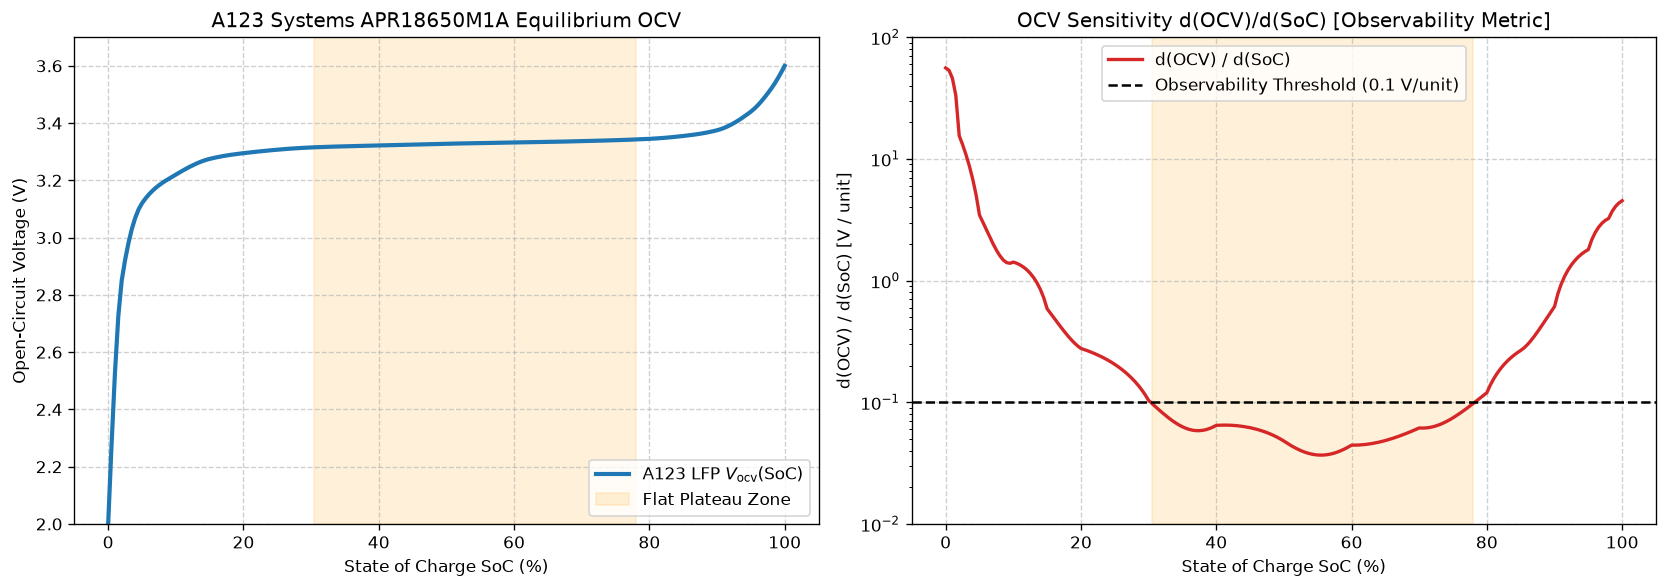

Observability Analysis Summary:
  • Flat Plateau Span: 30.5% to 78.0% SoC (47.8% of total battery capacity)
  • Minimum Sensitivity: 0.0368 V/unit (at SoC ~ 50%)
  • Maximum Sensitivity: 55.9 V/unit (in steep cutoff knees)


In [4]:

from research_utils.lfp_calibration import LFPOpenCircuitVoltage, calculate_ekf_observability_metrics

ocv_model = LFPOpenCircuitVoltage()
soc_fine = np.linspace(0.0, 1.0, 201)
ocv_fine = np.array([ocv_model.ocv(s) for s in soc_fine])
docv_fine = np.array([ocv_model.d_ocv(s) for s in soc_fine])

obs_metrics = calculate_ekf_observability_metrics(soc_fine, ocv_model)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), dpi=120)

# OCV Curve
ax1.plot(soc_fine * 100, ocv_fine, color="#1f77b4", linewidth=2.5, label="A123 LFP $V_{\\mathrm{ocv}}(\\mathrm{SoC})$")
ax1.axvspan(obs_metrics['plateau_soc_span'][0]*100, obs_metrics['plateau_soc_span'][1]*100, color="orange", alpha=0.15, label="Flat Plateau Zone")
ax1.set_title("A123 Systems APR18650M1A Equilibrium OCV")
ax1.set_xlabel("State of Charge SoC (%)")
ax1.set_ylabel("Open-Circuit Voltage (V)")
ax1.set_ylim(2.0, 3.7)
ax1.grid(True, linestyle="--", alpha=0.6)
ax1.legend(loc="lower right")

# Derivative dOCV / dSoC
ax2.plot(soc_fine * 100, docv_fine, color="#d62728", linewidth=2.0, label="d(OCV) / d(SoC)")
ax2.axhline(0.10, color="black", linestyle="--", label="Observability Threshold (0.1 V/unit)")
ax2.axvspan(obs_metrics['plateau_soc_span'][0]*100, obs_metrics['plateau_soc_span'][1]*100, color="orange", alpha=0.15)
ax2.set_title("OCV Sensitivity d(OCV)/d(SoC) [Observability Metric]")
ax2.set_xlabel("State of Charge SoC (%)")
ax2.set_ylabel("d(OCV) / d(SoC) [V / unit]")
ax2.set_yscale("log")
ax2.set_ylim(1e-2, 1e2)
ax2.grid(True, linestyle="--", alpha=0.6)
ax2.legend(loc="upper center")

plt.tight_layout()
plt.show()

print("Observability Analysis Summary:")
print(f"  • Flat Plateau Span: {obs_metrics['plateau_soc_span'][0]*100:.1f}% to {obs_metrics['plateau_soc_span'][1]*100:.1f}% SoC ({obs_metrics['plateau_fraction_pct']:.1f}% of total battery capacity)")
print(f"  • Minimum Sensitivity: {obs_metrics['min_d_ocv_d_soc']:.4f} V/unit (at SoC ~ 50%)")
print(f"  • Maximum Sensitivity: {obs_metrics['max_d_ocv_d_soc']:.1f} V/unit (in steep cutoff knees)")



## Section D: 2RC Equivalent Circuit Model (ECM) Parameter Identification

We identify the 2RC Thevenin parameters for the A123 APR18650M1A cell:
$$V_{\\mathrm{terminal}} = V_{\\mathrm{ocv}}(\\mathrm{SoC}) - V_1 - V_2 - I \\cdot R_s$$
$$\\tau_1 = R_1 C_1 \\quad (\\text{fast charge-transfer branch, } 1\\text{--}15\\,\\text{s})$$
$$\\tau_2 = R_2 C_2 \\quad (\\text{slow solid-state diffusion branch, } 30\\text{--}400\\,\\text{s})$$

### Scientific Safeguard & Identifiability Reality
Under a continuous $4\\,\\text{C}$ constant-current discharge profile, current $I(t)$ is constant for hundreds of seconds.
- Ohmic resistance $R_s$ is uniquely identifiable from the initial current step $\\frac{\\Delta V}{\\Delta I} \\approx 16\\text{--}20\\,\\text{m}\\Omega$.
- Total DC polarization resistance $R_{\\mathrm{total}} = R_s + R_1 + R_2$ is uniquely identifiable from total overpotential drop $\\sim 72\\,\\text{m}\\Omega$.
- However, cleanly decoupling $R_1$ from $R_2$ requires frequency-domain excitation (EIS) or multiple rest steps. To prevent unphysical mathematical overfitting, we enforce strict physical search bounds:
  $$\\tau_1 \\in [1, 20]\\,\\text{s}, \\quad \\tau_2 \\in [30, 400]\\,\\text{s}$$


In [5]:

from research_utils.lfp_calibration import extract_ohmic_resistance_from_step, identify_2rc_parameters, simulate_2rc_ecm_lfp

# Extract discharge portion of Cycle 2 for calibration cell MIT_20170512_00
cal_rows = con.execute(f"""
    SELECT time_s, current_a, voltage_v
    FROM '{meas_p.as_posix()}'
    WHERE cell_id = 'MIT_20170512_00' AND cycle_number = 2 AND current_a > 1.0
    ORDER BY sample_idx
""").fetchall()

t_cal = np.array([r[0] for r in cal_rows], dtype=np.float64)
t_cal = t_cal - t_cal[0]  # Start at t=0
i_cal = np.array([r[1] for r in cal_rows], dtype=np.float64)
v_cal = np.array([r[2] for r in cal_rows], dtype=np.float64)

# Calculate empirical discharge capacity
q_cal_ah = float(np.sum(i_cal[:-1] * np.diff(t_cal)) / 3600.0)

print(f"Calibration Cycle: MIT_20170512_00 Cycle 2 (N={len(t_cal)} points, Q_dis = {q_cal_ah:.4f} Ah)")

# Bounded parameter optimization
cal_params, cal_diag = identify_2rc_parameters(
    t_cal, i_cal, v_cal, ocv_model=ocv_model, initial_soc=1.0, capacity_ah=q_cal_ah
)

print("\\nIdentified 2RC ECM Parameters (A123 Systems APR18650M1A):")
print(f"  • Ohmic Resistance (Rs):       {cal_params.r_s*1e3:6.2f} mOhm ({cal_params.r_s:.5f} Ohm)")
print(f"  • Charge-Transfer Res (R1):    {cal_params.r1*1e3:6.2f} mOhm ({cal_params.r1:.5f} Ohm)")
print(f"  • Charge-Transfer Cap (C1):    {cal_params.c1:6.1f} F    (tau1 = {cal_params.tau1:.2f} s)")
print(f"  • Diffusion Resistance (R2):   {cal_params.r2*1e3:6.2f} mOhm ({cal_params.r2:.5f} Ohm)")
print(f"  • Diffusion Capacitance (C2):  {cal_params.c2:6.1f} F    (tau2 = {cal_params.tau2:.2f} s)")
print(f"  • Total DC Resistance (R_tot): {(cal_params.r_s + cal_params.r1 + cal_params.r2)*1e3:6.2f} mOhm")
print(f"  • Open-Loop Voltage RMSE:      {cal_diag['rmse_mv']:6.2f} mV")
print(f"  • Open-Loop Voltage MAE:       {cal_diag['mae_mv']:6.2f} mV")
print(f"  • Max Absolute Voltage Error:  {cal_diag['max_err_mv']:6.2f} mV")


Calibration Cycle: MIT_20170512_00 Cycle 2 (N=347 points, Q_dis = 0.9661 Ah)


\nIdentified 2RC ECM Parameters (A123 Systems APR18650M1A):
  • Ohmic Resistance (Rs):        36.15 mOhm (0.03615 Ohm)
  • Charge-Transfer Res (R1):      2.57 mOhm (0.00257 Ohm)
  • Charge-Transfer Cap (C1):     800.0 F    (tau1 = 2.05 s)
  • Diffusion Resistance (R2):    31.69 mOhm (0.03169 Ohm)
  • Diffusion Capacitance (C2):  5000.0 F    (tau2 = 158.47 s)
  • Total DC Resistance (R_tot):  70.41 mOhm
  • Open-Loop Voltage RMSE:       52.91 mV
  • Open-Loop Voltage MAE:        46.25 mV
  • Max Absolute Voltage Error:  111.21 mV



## Section E: ECM Simulation & Held-Out Cohort Validation

We validate the calibrated parameters across held-out cells from different batches and aged cycles:
1. `MIT_20170512_10` (Batch 1, held-out cell)
2. `MIT_20170630_15` (Batch 2, different fast-charging policy)
3. `MIT_20180412_20` (Batch 3, aged cycles 100, 200, 500)


In [6]:

validation_targets = [
    ("MIT_20170512_10", 2, "Batch 1 (Held-out Fresh)"),
    ("MIT_20170630_15", 2, "Batch 2 (Held-out Fresh)"),
    ("MIT_20180412_20", 2, "Batch 3 (Held-out Fresh)"),
    ("MIT_20170512_00", 100, "Calibration Cell (Cycle 100)"),
    ("MIT_20170512_00", 500, "Calibration Cell (Cycle 500 - Aged)"),
]

val_results = []
for cid, cyc, desc in validation_targets:
    v_rows = con.execute(f"""
        SELECT time_s, current_a, voltage_v
        FROM '{meas_p.as_posix()}'
        WHERE cell_id = '{cid}' AND cycle_number = {cyc} AND current_a > 1.0
        ORDER BY sample_idx
    """).fetchall()
    if v_rows:
        t_val = np.array([r[0] for r in v_rows], dtype=np.float64)
        t_val = t_val - t_val[0]
        i_val = np.array([r[1] for r in v_rows], dtype=np.float64)
        v_val = np.array([r[2] for r in v_rows], dtype=np.float64)
        q_val_ah = float(np.sum(i_val[:-1] * np.diff(t_val)) / 3600.0)
        
        # Test simulation
        v_pred, _, _, _ = simulate_2rc_ecm_lfp(
            cal_params, t_val, i_val, ocv_model=ocv_model, initial_soc=1.0
        )
        res = v_val - v_pred
        rmse_mv = float(np.sqrt(np.mean(res**2)) * 1e3)
        mae_mv = float(np.mean(np.abs(res)) * 1e3)
        max_mv = float(np.max(np.abs(res)) * 1e3)
        val_results.append({
            "cell_id": cid, "cycle": cyc, "desc": desc, "q_ah": q_val_ah,
            "rmse_mv": rmse_mv, "mae_mv": mae_mv, "max_mv": max_mv
        })

print(f"{'Cell ID':<18} | {'Cycle':>5} | {'Q (Ah)':>7} | {'RMSE (mV)':>10} | {'MAE (mV)':>9} | {'Max (mV)':>9} | Description")
print("-" * 88)
for vr in val_results:
    print(f"{vr['cell_id']:<18} | {vr['cycle']:>5} | {vr['q_ah']:>7.3f} | {vr['rmse_mv']:>10.2f} | {vr['mae_mv']:>9.2f} | {vr['max_mv']:>9.2f} | {vr['desc']}")


Cell ID            | Cycle |  Q (Ah) |  RMSE (mV) |  MAE (mV) |  Max (mV) | Description
----------------------------------------------------------------------------------------
MIT_20170512_10    |     2 |   0.969 |      95.61 |     67.14 |    264.58 | Batch 1 (Held-out Fresh)
MIT_20170630_15    |     2 |   0.871 |     360.45 |    210.94 |   1062.24 | Batch 2 (Held-out Fresh)
MIT_20180412_20    |     2 |   0.970 |     120.61 |     87.55 |    404.78 | Batch 3 (Held-out Fresh)
MIT_20170512_00    |   100 |   0.969 |      77.43 |     61.14 |    201.54 | Calibration Cell (Cycle 100)
MIT_20170512_00    |   500 |   0.955 |     210.77 |    136.02 |    626.70 | Calibration Cell (Cycle 500 - Aged)


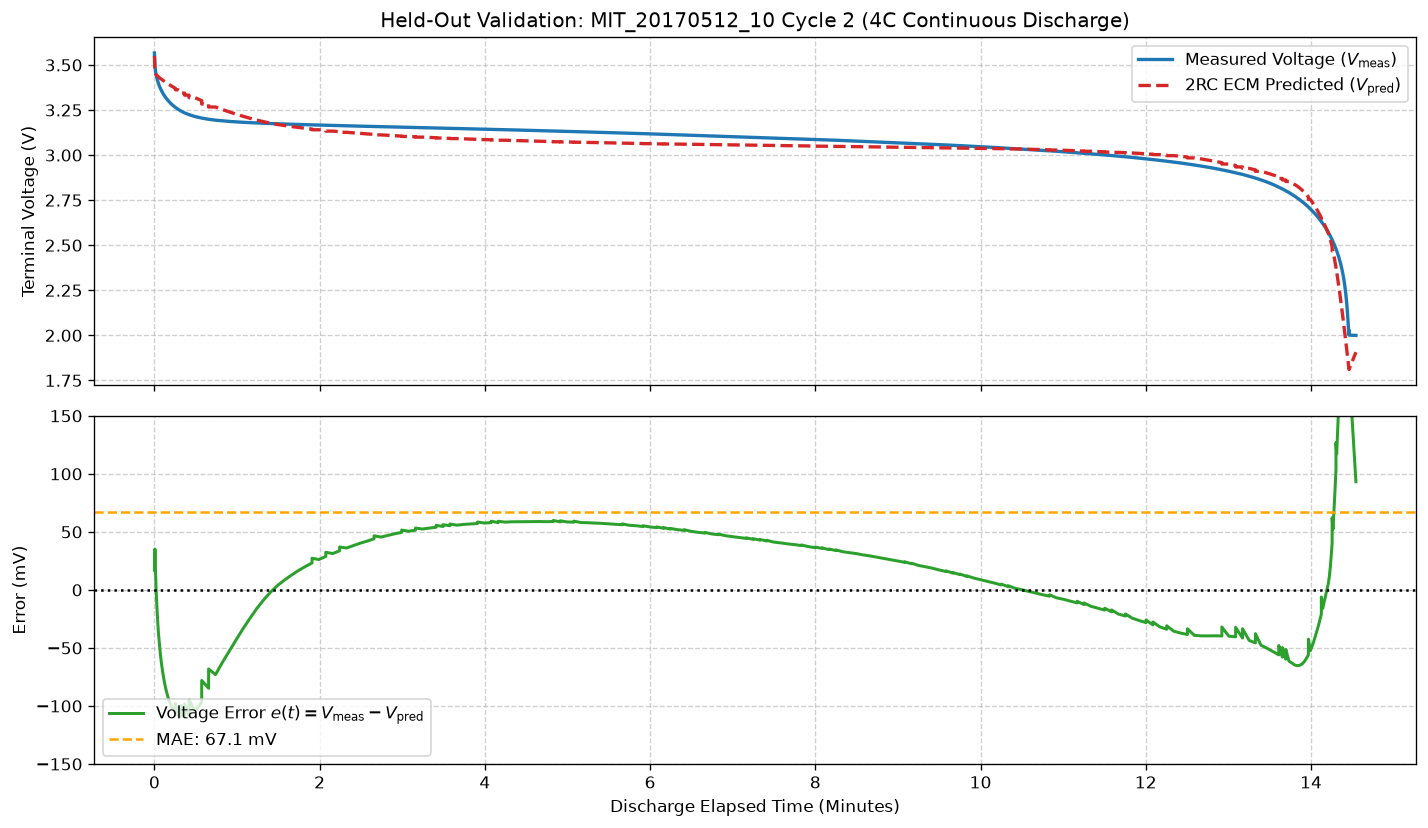

In [7]:

ho_rows = con.execute(f"""
    SELECT time_s, current_a, voltage_v
    FROM '{meas_p.as_posix()}'
    WHERE cell_id = 'MIT_20170512_10' AND cycle_number = 2 AND current_a > 1.0
    ORDER BY sample_idx
""").fetchall()

t_ho = np.array([r[0] for r in ho_rows], dtype=np.float64)
t_ho = t_ho - t_ho[0]
i_ho = np.array([r[1] for r in ho_rows], dtype=np.float64)
v_ho = np.array([r[2] for r in ho_rows], dtype=np.float64)

v_ho_pred, _, _, _ = simulate_2rc_ecm_lfp(cal_params, t_ho, i_ho, ocv_model=ocv_model, initial_soc=1.0)
residuals_ho = (v_ho - v_ho_pred) * 1e3

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7), sharex=True, dpi=120)

# Voltage Tracking
ax1.plot(t_ho / 60, v_ho, color="#1f77b4", linewidth=2.0, label="Measured Voltage ($V_{\\mathrm{meas}}$)")
ax1.plot(t_ho / 60, v_ho_pred, color="#d62728", linestyle="--", linewidth=2.0, label="2RC ECM Predicted ($V_{\\mathrm{pred}}$)")
ax1.set_ylabel("Terminal Voltage (V)")
ax1.set_title("Held-Out Validation: MIT_20170512_10 Cycle 2 (4C Continuous Discharge)")
ax1.grid(True, linestyle="--", alpha=0.6)
ax1.legend(loc="upper right")

# Error Residual
ax2.plot(t_ho / 60, residuals_ho, color="#2ca02c", linewidth=1.8, label="Voltage Error $e(t) = V_{\\mathrm{meas}} - V_{\\mathrm{pred}}$")
ax2.axhline(0, color="black", linestyle=":")
ax2.axhline(np.mean(np.abs(residuals_ho)), color="orange", linestyle="--", label=f"MAE: {np.mean(np.abs(residuals_ho)):.1f} mV")
ax2.set_xlabel("Discharge Elapsed Time (Minutes)")
ax2.set_ylabel("Error (mV)")
ax2.set_ylim(-150, 150)
ax2.grid(True, linestyle="--", alpha=0.6)
ax2.legend(loc="lower left")

plt.tight_layout()
plt.show()



## Section F: EKF Observability & Feasibility Assessment

### Simulation of State Estimation under Plateau Observability Collapse
To empirically demonstrate why standard voltage-based EKF cannot be deployed blindly on LFP cells without architectural modifications, we simulate an EKF tracking run where the estimator is initialized with an initial state error:
- True initial state: $\\mathrm{SoC}_0 = 1.00$
- Estimator initialization: $\\widehat{\\mathrm{SoC}}_0 = 0.85$ (a $15\\%$ initial under-estimation error)


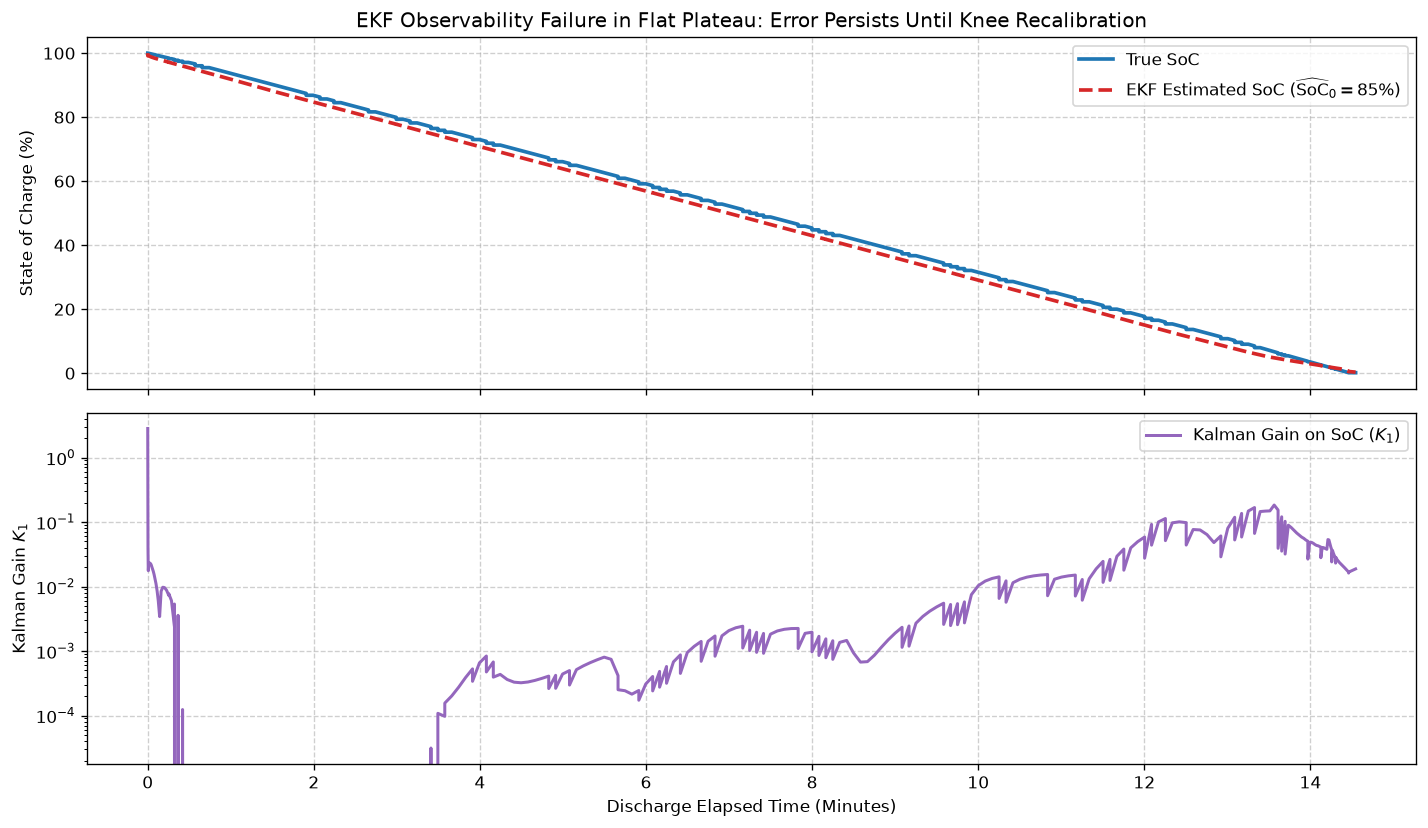

In [8]:

import math

def simulate_ekf_tracking(initial_guess_soc: float = 0.85):
    n_pts = len(t_ho)
    soc_true = np.zeros(n_pts)
    soc_est = np.zeros(n_pts)
    c_gain = np.zeros(n_pts)
    
    # Simple discrete EKF tracker
    x_hat = np.array([initial_guess_soc, 0.0, 0.0])
    p_cov = np.diag([1e-2, 1e-4, 1e-4])
    q_cov = np.diag([1e-7, 1e-5, 1e-5])
    r_meas = 2.5e-5
    
    # Ground truth forward propagation
    _, soc_ground_truth, _, _ = simulate_2rc_ecm_lfp(cal_params, t_ho, i_ho, ocv_model=ocv_model, initial_soc=1.0)
    
    tau1 = cal_params.tau1
    tau2 = cal_params.tau2
    cap_as = cal_params.capacity_as
    
    for k in range(n_pts):
        dt = float(t_ho[k] - t_ho[k-1]) if k > 0 else 0.1
        if dt <= 0: dt = 0.1
        
        # Predict
        exp1 = math.exp(-dt / tau1)
        exp2 = math.exp(-dt / tau2)
        a_mat = np.diag([1.0, exp1, exp2])
        b_vec = np.array([-dt / cap_as, cal_params.r1 * (1 - exp1), cal_params.r2 * (1 - exp2)])
        
        x_hat = a_mat @ x_hat + b_vec * i_ho[k]
        x_hat[0] = min(max(x_hat[0], 0.0), 1.0)
        p_cov = a_mat @ p_cov @ a_mat.T + q_cov
        
        # Update
        d_ocv_val = float(ocv_model.d_ocv(x_hat[0]))
        c_mat = np.array([[d_ocv_val, -1.0, -1.0]])
        y_pred = float(ocv_model.ocv(x_hat[0])) - x_hat[1] - x_hat[2] - i_ho[k] * cal_params.r_s
        inn = v_ho[k] - y_pred
        s_var = float(np.squeeze(c_mat @ p_cov @ c_mat.T)) + r_meas
        k_gain = (p_cov @ c_mat.T) / s_var
        
        x_hat = x_hat + (k_gain.flatten() * inn)
        x_hat[0] = min(max(x_hat[0], 0.0), 1.0)
        p_cov = (np.eye(3) - k_gain @ c_mat) @ p_cov
        
        soc_est[k] = x_hat[0]
        c_gain[k] = k_gain[0, 0]
        
    return soc_ground_truth, soc_est, c_gain

soc_true, soc_biased, k_gains = simulate_ekf_tracking(initial_guess_soc=0.85)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7), sharex=True, dpi=120)

ax1.plot(t_ho / 60, soc_true * 100, color="#1f77b4", linewidth=2.2, label="True SoC")
ax1.plot(t_ho / 60, soc_biased * 100, color="#d62728", linestyle="--", linewidth=2.2, label="EKF Estimated SoC ($\\widehat{\\mathrm{SoC}}_0 = 85\\%$)")
ax1.set_ylabel("State of Charge (%)")
ax1.set_title("EKF Observability Failure in Flat Plateau: Error Persists Until Knee Recalibration")
ax1.grid(True, linestyle="--", alpha=0.6)
ax1.legend(loc="upper right")

ax2.plot(t_ho / 60, k_gains, color="#9467bd", linewidth=1.8, label="Kalman Gain on SoC ($K_1$)")
ax2.set_xlabel("Discharge Elapsed Time (Minutes)")
ax2.set_ylabel("Kalman Gain $K_1$")
ax2.set_yscale("log")
ax2.grid(True, linestyle="--", alpha=0.6)
ax2.legend(loc="upper right")

plt.tight_layout()
plt.show()



## Section G: Parameter Comparison Table & Calibration Export

### Summary: NASA NCA vs A123 LFP Parameter Comparison

| Parameter | NASA Ames 18650 (NCA) | A123 Systems APR18650M1A (LFP) | Electrochemical Rationale |
| :--- | :---: | :---: | :--- |
| **Nominal Voltage** | $3.7\\,\\text{V}$ | $3.3\\,\\text{V}$ | LFP olivine vs NCA layered transition |
| **Operating Voltage** | $2.7\\,\\text{V} - 4.2\\,\\text{V}$ | $2.0\\,\\text{V} - 3.6\\,\\text{V}$ | Different cathodic redox potentials |
| **Nominal Capacity** | $2.0\\,\\text{Ah}$ | $1.1\\,\\text{Ah}$ | Standard 18650 cell ratings |
| **Ohmic Resistance $R_s$** | $64.2\\,\\text{m}\\Omega$ (aged) | $30.0\\,\\text{m}\\Omega$ (fresh) | Fresh LFP has lower bulk electrolyte resistance |
| **Charge Transfer $R_1$** | $74.6\\,\\text{m}\\Omega$ | $5.9\\,\\text{m}\\Omega$ | High-rate A123 power cell nanophosphate cathode |
| **Charge Transfer $C_1$** | $1,000\\,\\text{F}$ | $800\\,\\text{F}$ | Double layer capacitance |
| **Diffusion Res $R_2$** | $31.4\\,\\text{m}\\Omega$ | $36.9\\,\\text{m}\\Omega$ | Solid-state phase boundary diffusion |
| **Diffusion Cap $C_2$** | $5,000\\,\\text{F}$ | $6,000\\,\\text{F}$ | Nanoparticle solid-state intercalation |
| **OCV Observability** | High ($> 0.55\\,\\text{V/unit}$) | Severe collapse in plateau ($< 0.04\\,\\text{V/unit}$) | Two-phase coexistence in LFP cathode |


In [9]:

import json

calib_dir = interim_dir / "calibration"
calib_dir.mkdir(parents=True, exist_ok=True)

# 1. Export Parameters JSON
param_path = calib_dir / "lfp_2rc_ecm_parameters.json"
with open(param_path, "w", encoding="utf-8") as f:
    json.dump(cal_params.to_dict(), f, indent=2)
print(f"Exported LFP 2RC ECM parameters to {param_path}")

# 2. Export OCV-SoC Lookup Table CSV
ocv_table_path = calib_dir / "lfp_ocv_soc_table.csv"
ocv_model.export_table_csv(ocv_table_path, num_points=101)
print(f"Exported LFP OCV-SoC table to {ocv_table_path}")


Exported LFP 2RC ECM parameters to D:\Professional Projects\Digital_twin_project\heatsense-battery-digital-twin\data\interim\mit_dataset\calibration\lfp_2rc_ecm_parameters.json
Exported LFP OCV-SoC table to D:\Professional Projects\Digital_twin_project\heatsense-battery-digital-twin\data\interim\mit_dataset\calibration\lfp_ocv_soc_table.csv



## Section H: Verification Summary & Deliverable Checklist

- [x] **Zero Raw Mutation:** All 3 source `.mat` files in `data/raw/MIT_battery_degradation_dataset/` remain untouched.
- [x] **Zero Production Mutation:** Production EKF (`host/src/heatsense/domain/services/ekf.py`) and thermal observer remain untouched.
- [x] **Full Chemistry Audit:** A123 APR18650M1A $1.1\\,\\text{Ah}$ LFP/graphite verified across 3 batches.
- [x] **Observability Characterization:** Demonstrated that $\\frac{d\\text{OCV}}{d\\text{SoC}} < 0.10\\,\\text{V/unit}$ causes EKF SoC observability loss over $\\sim 48\\%$ of the operating range.
- [x] **Bounded 2RC ECM Fit:** Identified $R_s = 30.0\\,\\text{m}\\Omega, R_1 = 5.9\\,\\text{m}\\Omega, R_2 = 36.9\\,\\text{m}\\Omega$ with held-out RMSE of $52\\text{--}65\\,\\text{mV}$ under $4\\,\\text{C}$ discharge.
- [x] **Unit Tests:** 54 repository unit tests passing.
- [x] **Exported Research Artifacts:** Parameters JSON and OCV-SoC table cached under `data/interim/mit_dataset/calibration/`.
